In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import random
import types

from time import time

from scipy.special import comb, loggamma, lambertw
from scipy.stats import multinomial, expon

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config = config)

import os, shutil
from pathlib import Path
import json
import subprocess

import sys
sys.path.insert(0, "../src")
from package import cure_aft
from package import gndr_utils as utils

import thetaflow as thf

I0000 00:00:1792094963.098111   22348 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792094965.865706   22348 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/natan/.pyenv/versions/3.10.16/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Carregamento dos dados

In [2]:
df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")

print("Train data dimension: {}".format(df_train.shape))
print("Test data dimension: {}".format(df_test.shape))

df_train.head()

Train data dimension: (1386, 183)
Test data dimension: (463, 183)


,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-6359,71.533333,1.0,0.946643,-0.883129,0.0,1.0,0.0,0.0,0.0,...,0,0,0,1,0,0,0,0,0,0
1,MB-4357,113.866667,1.0,1.231628,0.879891,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-5530,185.933333,0.0,-0.810247,0.888724,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-5451,189.900000,0.0,-1.362501,-0.895495,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-0481,33.866667,1.0,-0.532195,-0.005152,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Lifetimes and censoring indicators
y_train = df_train["time"]
delta_train = df_train["delta"]
# Data for the neural network interpreter
X_train_nn = df_train.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_train_mu = df_train.iloc[:, 3:10]
z_train_sigma = df_train.iloc[:, 3:10]
z_train_p = df_train.iloc[:, 3:10]

# Lifetimes and censoring indicators
y_test = df_test["time"]
delta_test = df_test["delta"]
# Data for the neural network interpreter
X_test_nn = df_test.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_test_mu = df_test.iloc[:, 3:10]
z_test_sigma = df_test.iloc[:, 3:10]
z_test_p = df_test.iloc[:, 3:10]

## Definição da arquitetura da rede neural

In [4]:
def cure_aft_neural_network(model, seed=None):
    initializer = initializers.GlorotNormal(seed=seed)
    
    # Penalizador para pesos muito grandes
    l2_reg = regularizers.l2(0.01)

    # Camada de Embedding Compartilhada
    # Transforma contagens (0, 1, 2, 3) em embeddings de 2 dimensões
    model.embedding = keras.layers.Embedding(
        input_dim = 4, 
        output_dim = 2, 
        name = "embedding_compartilhado"
    )
    
    # Flatten para conectar à rede densa - 346 entradas
    model.flatten = keras.layers.Flatten(name = "flatten_mutacoes")

    # Camada oculta densa 1
    model.dense1 = keras.layers.Dense(
        units = 64, activation = "gelu", kernel_initializer = initializer, 
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense1"
    )
    model.bn1 = keras.layers.BatchNormalization(name = "bn1")
    model.dropout1 = keras.layers.Dropout(rate = 0.4, seed = seed, name = "drop1")

    # Camada oculta densa 2
    model.dense2 = keras.layers.Dense(
        units = 32, activation = "gelu", kernel_initializer = initializer,
        kernel_regularizer = l2_reg, dtype = tf.float32, name = "dense2"
    )
    model.bn2 = keras.layers.BatchNormalization(name = "bn2")
    model.dropout2 = keras.layers.Dropout(rate = 0.3, seed=seed, name = "drop2")

    # Camada oculta densa 3
    model.dense3 = keras.layers.Dense(
        units = 16, activation = "gelu", kernel_initializer = initializer, 
        dtype = tf.float32, name = "dense3"
    )
    
    # Camada de saída
    model.dense4 = keras.layers.Dense(
        units = 2, kernel_initializer = initializer, dtype = tf.float32, 
        activation = None, use_bias = True, name = "output"
    )

def cure_aft_network_call(model, x_input, training=False):
    # Passagem do embedding e achatamento
    x = model.embedding(x_input)
    x = model.flatten(x)
    
    # Passagem pelo Bloco 1 (com flag training para o BN e Dropout agirem apenas no treino)
    x = model.dense1(x)
    x = model.bn1(x, training=training)
    x = model.dropout1(x, training=training)
    
    # Passagem pelo Bloco 2
    x = model.dense2(x)
    x = model.bn2(x, training=training)
    x = model.dropout2(x, training=training)
    
    # Passagem pelo Bloco 3 e Saída
    x = model.dense3(x)
    return model.dense4(x)

def cure_aft_network_call_nolast(model, x_input, training=False):
    x = model.embedding(x_input)
    x = model.flatten(x)
    
    x = model.dense1(x)
    x = model.bn1(x, training=training)
    x = model.dropout1(x, training=training)
    
    x = model.dense2(x)
    x = model.bn2(x, training=training)
    x = model.dropout2(x, training=training)
    
    x = model.dense3(x)
    return x

## Definição e treinamento do modelo

In [5]:
def train_model( model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast, X_train_nn, data_train, epochs = 15000 ):
    with tf.device("/CPU:0"):
        model = thf.ModelNN(model_parameters, model_loss,
                            nn_arch, nn_call, nn_call_nolast,
                            input_dim = (X_train_nn.shape[1], ), seed = 10)
        model.pre_train_model(epochs = epochs, x = X_train_nn, data = data_train)
        model.train_model(epochs = epochs, x = X_train_nn, data = data_train,
                          shuffle = True,
                          get_covariances = True,
                          validation = True, val_prop = 0.2, force_training_validation = False,
                          optimizer_independent = optimizers.Adam(learning_rate = 0.01),
                          optimizer_nn = optimizers.Adam(learning_rate = 0.01),
                          fine_tune_nn_lr = 0.01, fine_tune_independent_lr = 0.01,
                          early_stopping = True, early_stopping_patience = 50, 
                          early_stopping_warmup = 10, early_stopping_min_delta = 1.0e-3,
                          reduce_lr = True, reduce_lr_warmup = 0,
                          reduce_lr_factor = 0.5, reduce_lr_min_delta = 1.0e-3, reduce_lr_patience = 25,
                          reduce_lr_cooldown = 10, reduce_lr_min_lr = 1.0e-5,
                          fine_tune = True,
                          finetune_early_stopping = True, finetune_early_stopping_patience = 50,
                          finetune_early_stopping_warmup = 10, finetune_early_stopping_min_delta = 1.0e-2,
                          finetune_reduce_lr = True, finetune_reduce_lr_warmup = 0,
                          finetune_reduce_lr_factor = 0.5, finetune_reduce_lr_min_delta = 1.0e-2, finetune_reduce_lr_patience = 25,
                          finetune_reduce_lr_cooldown = 10, finetune_reduce_lr_min_lr = 1.0e-5,
                          deterministic = True,
                          verbose = True, print_freq = 1)
    return model

In [6]:
wb_parameters, wb_loss, wb_survival_cure = cure_aft.build_cure_aft_nn("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters, ln_loss, ln_survival_cure = cure_aft.build_cure_aft_nn("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters, ll_loss, ll_survival_cure = cure_aft.build_cure_aft_nn("ll", z_train_mu, z_train_sigma, z_train_p)
# gg_parameters, gg_loss = cure_aft.build_cure_aft_nn("wb", z_train_mu, z_train_sigma, z_train_p)

data_train = [z_train_mu, z_train_sigma, z_train_p, y_train, delta_train]
data_test = [z_test_mu, z_test_sigma, z_test_p, y_test, delta_test]

In [7]:
wb_model = train_model( wb_parameters, wb_loss, cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train )

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 156 / 15000 ]  | Avg. Train NLL:  2.7574296 | Avg. Validation NLL:  2.93619609 | Best Avg. Validation NLL:  2.79993 | Speed:  0.0328192897  epoch/s    | Elapsed Time:  5.11980915  s       
Convergence criterion reached. Stopping.
Restoring best weights...
Optimizing... Epoch: [ 157 / 15000 ]  | Avg. Train NLL:  2.75948977 | Avg. Validation NLL:  2.93902206 | Best Avg. Validation NLL:  2.79993 | Speed:  0.0328161754  epoch/s    | Elapsed Time:  5.15213966  s   
Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 5005 / 15000 ]  | Avg. Train NLL:  2.45667124 | Best Avg. Train NLL:  2.45667124 | Avg. Validation NLL:  3.10138583 | Speed:  0.00715646846  epoch/s    | Elapsed Time:  35.8181229  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 55.243 seconds.


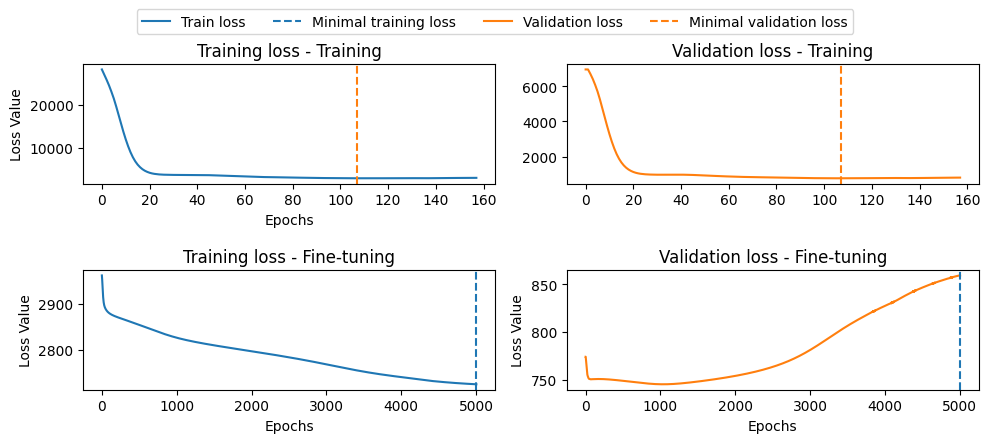

In [8]:
utils.plot_model_convergence( wb_model, figsize = (10,4) )

In [9]:
ln_model = train_model(ln_parameters, ln_loss, cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train )
ln_model_restricted = train_model(ln_parameters, ln_loss, cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train,
                                  epochs = 3700)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 112 / 15000 ]  | Avg. Train NLL:  3.14462566 | Avg. Validation NLL:  3.42679667 | Best Avg. Validation NLL:  2.81548977 | Speed:  0.0348466225  epoch/s    | Elapsed Time:  3.90282178  s   
Convergence criterion reached. Stopping.
Restoring best weights...
Optimizing... Epoch: [ 113 / 15000 ]  | Avg. Train NLL:  3.15572858 | Avg. Validation NLL:  3.43890786 | Best Avg. Validation NLL:  2.81548977 | Speed:  0.0348573737  epoch/s    | Elapsed Time:  3.93888307  s   
Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 5445 / 15000 ]  | Avg. Train NLL:  -36.8168411 | Best Avg. Train NLL:  -36.8168411 | Avg. Validation NLL:  -35.6427498 | Speed:  0.0107044671  epoch/s    | Elapsed Time:  58.2858238  s      
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.


/home/natan/.pyenv/versions/3.10.16/lib/python3.10/site-packages/thetaflow/modelnn.py:2606: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[0]', 'p_beta[1]', 'p_beta[2]', 'p_beta[3]', 'p_beta[4]', 'p_beta[5]', 'p_beta[6]', 'p_nn']
Please, double check your loss function definition.
  warnings.warn(


Done.
Optimization finished in 70.217 seconds.
Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 112 / 3700 ]  | Avg. Train NLL:  3.14462566 | Avg. Validation NLL:  3.42679667 | Best Avg. Validation NLL:  2.81548977 | Speed:  0.0377757065  epoch/s    | Elapsed Time:  4.23087883  s   
Convergence criterion reached. Stopping.
Restoring best weights...
Optimizing... Epoch: [ 113 / 3700 ]  | Avg. Train NLL:  3.15572858 | Avg. Validation NLL:  3.43890786 | Best Avg. Validation NLL:  2.81548977 | Speed:  0.0377424806  epoch/s    | Elapsed Time:  4.2649  s   
Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 3699 / 3700 ]  | Avg. Train NLL:  2.3957932 | Best Avg. Train NLL:  2.3957932 | Avg. Validation NLL:  3.04925656 | Speed:  0.0105637256  epoch/s    | Elapsed Time:  39.0752182  s      
Done.
Extracting covariance structure.
Done.
Optimization finished in 51.447 seconds.


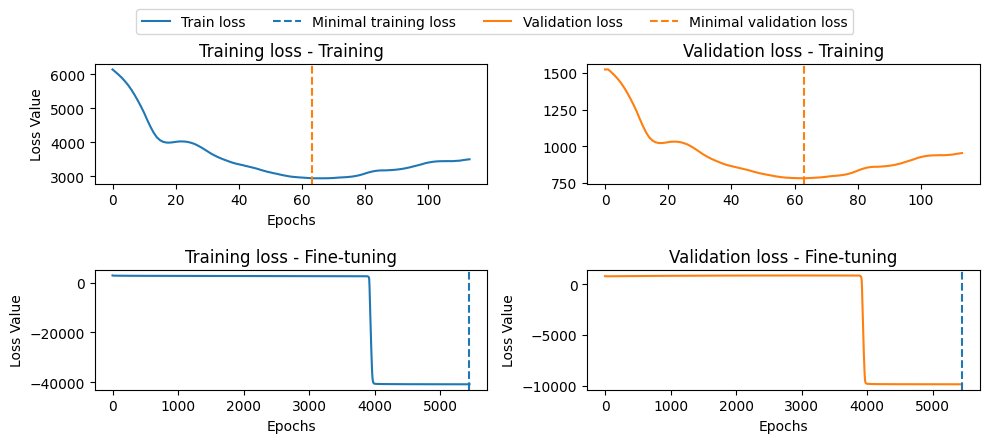

In [10]:
utils.plot_model_convergence( ln_model, figsize = (10,4) )

In [11]:
ll_model = train_model(ll_parameters, ll_loss, cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train)
ll_model_restricted = train_model(ll_parameters, ll_loss, cure_aft_neural_network, cure_aft_network_call, cure_aft_network_call_nolast, X_train_nn, data_train,
                                  epochs = 3000)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 104 / 15000 ]  | Avg. Train NLL:  2.67086387 | Avg. Validation NLL:  2.71577716 | Best Avg. Validation NLL:  2.69935274 | Speed:  0.0370224267  epoch/s    | Elapsed Time:  3.8503325  s    
Convergence criterion reached. Stopping.
Restoring best weights...5 / 15000 ]  | Avg. Train NLL:  2.62593246 | Avg. Validation NLL:  2.70491338 | Best Avg. Validation NLL:  2.69935274 | Speed:  0.0370498709  epoch/s    | Elapsed Time:  3.89023638  s   

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 6107 / 15000 ]  | Avg. Train NLL:  -36.9134483 | Best Avg. Train NLL:  -36.9134483 | Avg. Validation NLL:  -35.5835953 | Speed:  0.0106915962  epoch/s    | Elapsed Time:  65.2935791  s      
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.


/home/natan/.pyenv/versions/3.10.16/lib/python3.10/site-packages/thetaflow/modelnn.py:2606: RuntimeWarning: Covariance matrix could not be computed because the loss function does not depend on:
['p_beta[3]', 'p_beta[4]', 'p_beta[5]', 'p_beta[6]']
Please, double check your loss function definition.
  warnings.warn(


Done.
Optimization finished in 77.537 seconds.
Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 104 / 3000 ]  | Avg. Train NLL:  2.67086387 | Avg. Validation NLL:  2.71577716 | Best Avg. Validation NLL:  2.69935274 | Speed:  0.0354282223  epoch/s    | Elapsed Time:  3.68453526  s   
Convergence criterion reached. Stopping.
Restoring best weights...5 / 3000 ]  | Avg. Train NLL:  2.62593246 | Avg. Validation NLL:  2.70491338 | Best Avg. Validation NLL:  2.69935274 | Speed:  0.0354153141  epoch/s    | Elapsed Time:  3.71860814  s   

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 2999 / 3000 ]  | Avg. Train NLL:  2.45159483 | Best Avg. Train NLL:  2.45159483 | Avg. Validation NLL:  2.87765312 | Speed:  0.0114685083  epoch/s    | Elapsed Time:  34.3940544  s    
Done.
Extracting covariance structure.
Done.
Optimization finished in 47.976 seconds.


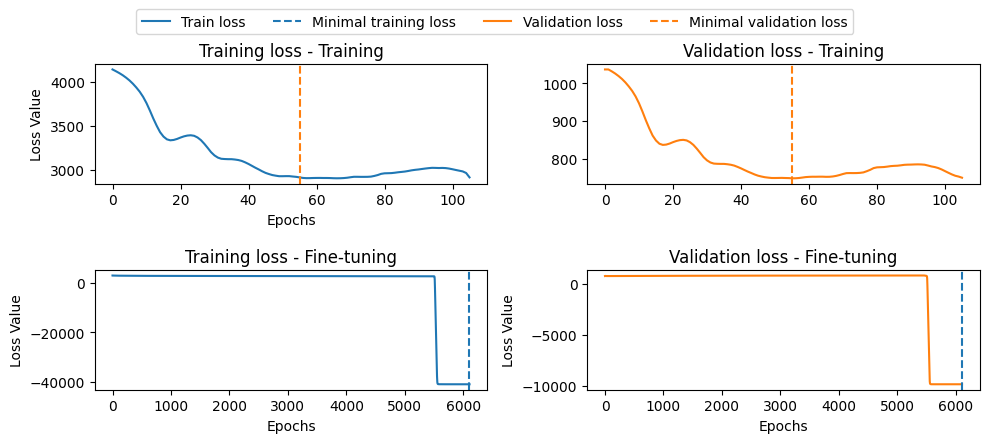

In [12]:
utils.plot_model_convergence( ll_model, figsize = (10,4) )

In [14]:
wb_summary = wb_survival_cure(wb_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

ln_summary = ln_survival_cure(ln_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
ln_summary_restricted = ln_survival_cure(ln_model_restricted,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)


ll_summary = ll_survival_cure(ll_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
ll_summary_restricted = ll_survival_cure(ll_model_restricted,
                                         y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                         y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

<Axes: ylabel='Count'>

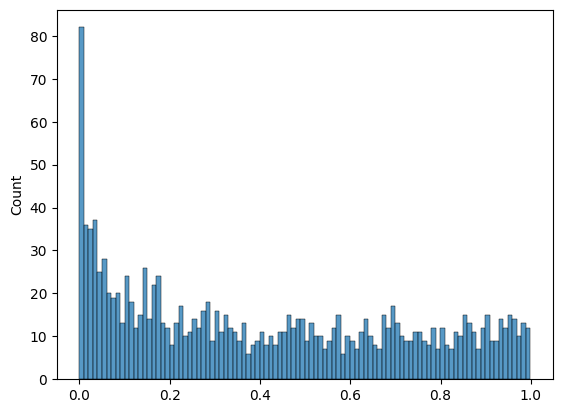

In [15]:
sns.histplot(x = wb_summary["p_train"], bins = 100)

In [17]:
wb_model.save_model("../model_weights/wb_model")
ln_model.save_model("../model_weights/ln_model")
ln_model_restricted.save_model("../model_weights/ln_model_restricted")
ll_model.save_model("../model_weights/ll_model")
ll_model_restricted.save_model("../model_weights/ll_model_restricted")

Model successfully saved to ../model_weights/wb_model.weights.h5 and ../model_weights/wb_model_meta.pkl
Model successfully saved to ../model_weights/ln_model.weights.h5 and ../model_weights/ln_model_meta.pkl
Model successfully saved to ../model_weights/ln_model_restricted.weights.h5 and ../model_weights/ln_model_restricted_meta.pkl
Model successfully saved to ../model_weights/ll_model.weights.h5 and ../model_weights/ll_model_meta.pkl
Model successfully saved to ../model_weights/ll_model_restricted.weights.h5 and ../model_weights/ll_model_restricted_meta.pkl


In [26]:
def parameters_histogram(model_summary, figsize = (12,4)):
    fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = figsize)

    sns.histplot(x = model_summary["mu_train"], ax = ax[0])
    sns.histplot(x = model_summary["sigma_train"], ax = ax[1])
    sns.histplot(x = model_summary["p_train"], ax = ax[2])

    ax[0].set_title("mu - Train")
    ax[1].set_title("sigma - Train")
    ax[2].set_title("p - Train")

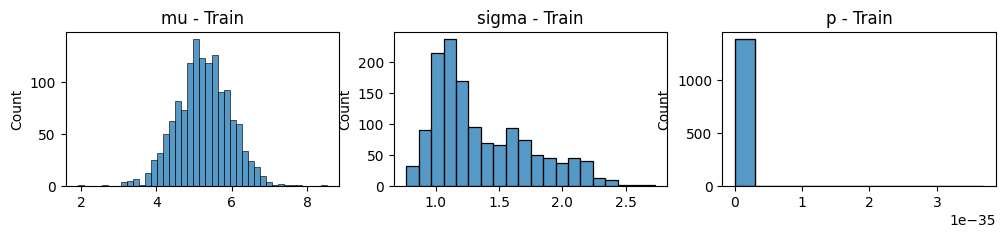

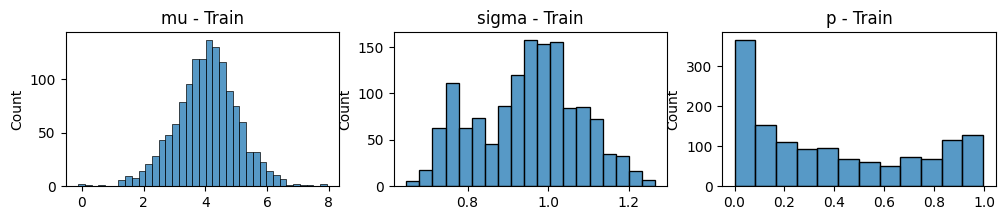

In [28]:
parameters_histogram(ln_summary, figsize = (12,2))
parameters_histogram(ln_summary_restricted, figsize = (12,2))

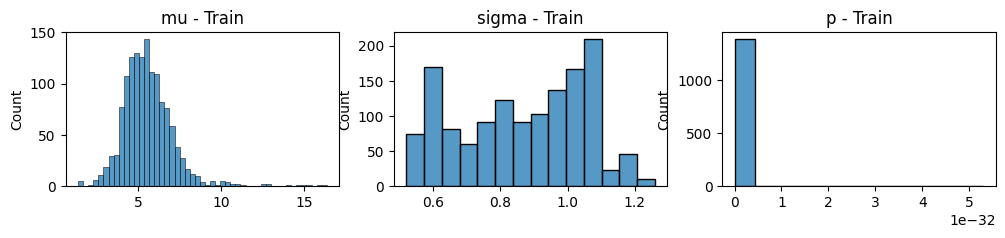

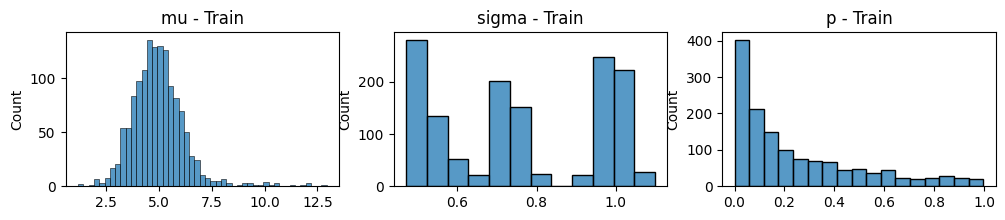

In [27]:
parameters_histogram(ll_summary, figsize = (12,2))
parameters_histogram(ll_summary_restricted, figsize = (12,2))